## 🔑Config

In [1]:
# B Score model configuration
# ─────────────────────────────────────────────────────────────────────────────
from google.cloud import bigquery
import time
import pandas as pd
from datetime import datetime

# client = bigquery.Client()
CURRENT_DATE = datetime.now().strftime("%Y%m%d")

# Schema and table name definitions (update OBDATE for each model run)
schema1 = 'risk_mart'
schema2 = 'worktable_data_analysis'
schema3 = 'dap_ds_poweruser_playground'

UTIL_PATH = r"D:\OneDrive - Tonik Financial Pte Ltd\MyStuff\Data Engineering\Model_Data_Set_preparation\DC_Model_Data_Sets_Feature_Universe\Feature_Universe_Training_Config"

# UTIL_PATH = F"D:\Officedata\Feature_Universe_Training"

GS_BUCKET = "prod-asia-southeast1-tonik-report-analytics"
GS_BUCKET_OLD = "prod-asia-southeast1-tonik-aiml-workspace"
PROJECT_ID = "prj-prod-dataplatform"

tab = 'bscore'
ver = 'v28'

OBDATE = '2026-10-12'   # Observation date — update for each scoring run
SDATE  = '2023-01-01'   # Start date for training window
EDATE  = OBDATE

formatted_date = datetime.strptime(SDATE, '%Y-%m-%d').strftime('%Y%m%d')
ob_formatted   = datetime.strptime(OBDATE, '%Y-%m-%d').strftime('%Y%m%d')

al       = f'applied_loans_20230101_{ob_formatted}'
altrans  = f'applied_loans_20210701_{ob_formatted}_trans'
nal      = f'tsa_onboarded_but_never_applied_loan_20230101_{ob_formatted}'

# Intermediate staging tables
bscorebasedata = f'{tab}_base_data_{ver}_{datetime.strptime(SDATE, '%Y-%m-%d').strftime('%Y%m%d')}_{datetime.strptime(OBDATE, '%Y-%m-%d').strftime('%Y%m%d')}'
print(bscorebasedata)
bscoresnapshotcustomerdata        = f'{tab}_applied_loans_customer_information_data_{ver}'
bscoresnapshotcustomertransactiondata = f'{tab}_applied_loans_customer_transaction_data_{ver}'
bscoresnapshotcustomerevent       = f'{tab}_applied_loans_customer_event_data_{ver}'
bscoresnapshotcontactability      = f'{tab}_applied_loans_contactability_{ver}'
bscoresnapshotcombineddata        = f'{tab}_model_applied_loans_{ver}_{ob_formatted}'


step61 = f'{schema2}.{tab}_vb_results_{ver}_{ob_formatted}'
step62 = f'{schema2}.{tab}_chatbot_{ver}_{ob_formatted}'
step63 = f'{schema2}.{tab}_chatbot_fb_{ver}_{ob_formatted}'
step64 = f'{schema2}.{tab}_chatbot_users_{ver}_{ob_formatted}'
step65 = f'{schema2}.{tab}_genesys_chat_{ver}_{ob_formatted}'
step66 = f'{schema2}.{tab}_genesys_email_{ver}_{ob_formatted}'
step67 = f'{schema2}.{tab}_inbound_voice_{ver}_{ob_formatted}'
step68 = f'{schema2}.{tab}_airudder_softcollection_calls_{ver}_{ob_formatted}'
step682 = f'{schema2}.{tab}_cs_vb_cnt_calls_total_{ver}_{ob_formatted}'
step69 = f'{schema2}.{tab}_reach_enhanced_{ver}_{ob_formatted}'
step610 = f'{schema2}.{tab}_ars_results_{ver}_{ob_formatted}'
step611 = f'{schema2}.{tab}_inbound_additional_features_{ver}_{ob_formatted}'
step612 = f'{schema2}.{tab}_outbound_voice_features_{ver}_{ob_formatted}'
step6 = f'{schema2}.{tab}_contact_features_extended_{ver}_{ob_formatted}'
step7 = f'{schema2}.{tab}_contact_genesysdata_{ver}_{ob_formatted}'
step8 = f'{schema2}.{tab}_loan_level_swathi_table_{ver}_{ob_formatted}'
step9 = f'{schema2}.{tab}_ptp_details_{ver}_{ob_formatted}'

step101 = f'{schema2}.{tab}_account_product_portfolio_composition_{ver}_{ob_formatted}'
step102 = f'{schema2}.{tab}_activity_recency_dormancy_{ver}_{ob_formatted}'
step103 = f'{schema2}.{tab}_tx_balance_liquidity_{ver}_{ob_formatted}'
step104 = f'{schema2}.{tab}_bureau_external_scoring_{ver}_{ob_formatted}'
step105 = f'{schema2}.{tab}_completion_settlement_metrics_{ver}_{ob_formatted}'
step106 = f'{schema2}.{tab}_conversion_campaign_engagement_events_{ver}_{ob_formatted}'
step107 = f'{schema2}.{tab}_customer_acquisition_retention_{ver}_{ob_formatted}'
step108 = f'{schema2}.{tab}_customer_lifecycle_engagement_{ver}_{ob_formatted}'
step109 = f'{schema2}.{tab}_demographic_verification_enhanced_{ver}_{ob_formatted}'
step1010 = f'{schema2}.{tab}_deposit_savings_products_{ver}_{ob_formatted}'
step1011 = f'{schema2}.{tab}_derived_ratio_metrics_{ver}_{ob_formatted}'
step1012 = f'{schema2}.{tab}_fraud_compliance_indicators_{ver}_{ob_formatted}'
step1013 = f'{schema2}.{tab}_loan_product_specific_metrics_{ver}_{ob_formatted}'
step1014 = f'{schema2}.{tab}_loan_staging_milestones_{ver}_{ob_formatted}'
step10151 = f'{schema2}.{tab}_payment_behaviour_advanced_{ver}_{ob_formatted}'
step10152 = f'{schema2}.{tab}_payment_behaviour_advanced_2_{ver}_{ob_formatted}'
step1016 = f'{schema2}.{tab}_revenue_fee_decomposition_{ver}_{ob_formatted}'
step1017 = f'{schema2}.{tab}_risk_segmentation_categorization_{ver}_{ob_formatted}'
step1018 = f'{schema2}.{tab}_time_window_cohort_features_{ver}_{ob_formatted}'
step1019 = f'{schema2}.{tab}_transaction_volume_type_breakdown_{ver}_{ob_formatted}'
step111 = f'{schema2}.{tab}_collection_call_features_{ver}_{ob_formatted}'
step112 = f'{schema2}.{tab}_payhinga_features_{ver}_{ob_formatted}'

step12c = f'{schema2}.PH_City_Province_Event_Mapping_{ver}_{ob_formatted}'

step12d = f'{schema2}.{tab}_ph_shock_feature_{ver}_{ob_formatted}'
step14 = f'{schema2}.{tab}_prevloan_less_6dpd_details_{ver}_{ob_formatted}'

step17 = f'{schema2}.{tab}_customer_level_5dpd_details_{ver}_{ob_formatted}'

step20 = f'dap_ds_poweruser_playground.{tab}_yuvashri_features_{ver}_{ob_formatted}'

step22 = f'{schema2}.{tab}_finscore_{ver}_{ob_formatted}'
step23 = f'{schema2}.{tab}_trustingsocialscore_{ver}_{ob_formatted}'
step24 = f'{schema2}.{tab}_bureauinc_score_{ver}_{ob_formatted}'

for step_name, step_value in {
    "step61": step61,
    "step62": step62,
    "step63": step63,
    "step64": step64,
    "step65": step65,
    "step66": step66,
    "step67": step67,
    "step68": step68,
    "step682": step682,
    "step69": step69,
    "step610": step610,
    "step611": step611,
    "step612": step612,
    "step6": step6,
    "step7": step7,
    "step8": step8,
    "step9": step9,
    "step101": step101,
    "step102": step102,
    "step103": step103,
    "step104": step104,
    "step105": step105,
    "step106": step106,
    "step107": step107,
    "step108": step108,
    "step109": step109,
    "step1010": step1010,
    "step1011": step1011,
    "step1012": step1012,
    "step1013": step1013,
    "step1014": step1014,
    "step10151": step10151,
    "step10152": step10152,
    "step1016": step1016,
    "step1017": step1017,
    "step1018": step1018,
    "step1019": step1019,
    "step111": step111,
    "step112": step112,
    "step12c": step12c,
    "step12d": step12d,
    "step14": step14,
    "step17": step17,
    "step20": step20,
    "step22": step22,
    "step23": step23,
    "step24": step24,
}.items():
    print(f"{step_name}: {step_value}")



# Final output tables (split by loan type)
trench3_b_score_model_applied_loans = f'{tab}_model_applied_loans_app_package_{ver}_{ob_formatted}'

print(f"OBDATE: {OBDATE}")
print(f"Output table: {schema2}.{bscoresnapshotcombineddata}")

print(f"Applied Table: {schema1}.{al}")
print(f"Applied Trans Table: {schema1}.{altrans}")
print(f"tsa_onboarded_but_never_applied_loan Table: {schema1}.{nal}")

APP_PACKAGE = f'{tab}_applied_all_dis_loan_app_package_{ver}_{ob_formatted}'
print(f"App Package Table: {schema2}.{APP_PACKAGE}")

App_Feature_Table = f'{tab}_model_app_features_{ver}_{ob_formatted}'
print(f"App Feature Table: {schema2}.{App_Feature_Table}")

cic_feature_table = f'{tab}_cic_features_{ver}_{ob_formatted}'
print(f"CIC Feature Table: {schema2}.{tab}_cic_features_{ver}_{ob_formatted}")

android_devise_score_features = f"{tab}_android_device_score_feature_list_{ver}_{ob_formatted}"
print(f"Android Device Score Feature Table: {schema2}.{android_devise_score_features}")

ios_device_score_features = f"{tab}_ios_device_score_features_{ver}_{ob_formatted}"
print(f"iOS Device Score Feature Table: {schema2}.{ios_device_score_features}")

nitin_event_features = f"{schema2}.{tab}_events_feats_{ver}_{ob_formatted}"
print(f"nitin_event_features Table: {nitin_event_features}")

demo_features = f"{schema3}.{tab}_demo_features_{ver}"
print(f"Demo Feature Table: {demo_features}")
stepfinaltab = f"{schema2}.{tab}_model_full_features_v7_{ver}_{ob_formatted}"
print(f"Final Feature Table: {stepfinaltab}")

finaltab = f"{schema2}.{tab}_model_full_features_model_dataset_{ver}_{ob_formatted}"
print(f"Final Table: {finaltab}")

bscore_base_data_v28_20230101_20261012
step61: worktable_data_analysis.bscore_vb_results_v28_20261012
step62: worktable_data_analysis.bscore_chatbot_v28_20261012
step63: worktable_data_analysis.bscore_chatbot_fb_v28_20261012
step64: worktable_data_analysis.bscore_chatbot_users_v28_20261012
step65: worktable_data_analysis.bscore_genesys_chat_v28_20261012
step66: worktable_data_analysis.bscore_genesys_email_v28_20261012
step67: worktable_data_analysis.bscore_inbound_voice_v28_20261012
step68: worktable_data_analysis.bscore_airudder_softcollection_calls_v28_20261012
step682: worktable_data_analysis.bscore_cs_vb_cnt_calls_total_v28_20261012
step69: worktable_data_analysis.bscore_reach_enhanced_v28_20261012
step610: worktable_data_analysis.bscore_ars_results_v28_20261012
step611: worktable_data_analysis.bscore_inbound_additional_features_v28_20261012
step612: worktable_data_analysis.bscore_outbound_voice_features_v28_20261012
step6: worktable_data_analysis.bscore_contact_features_extended_v

In [3]:

# %% [markdown]
# # Jupyter Notebook Loading Header
#
# This is a custom loading header for Jupyter Notebooks in Visual Studio Code.
# It includes common imports and settings to get you started quickly.
# %% [markdown]
## Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.cloud import bigquery
from google.cloud import storage
import os

import time
from datetime import datetime
import uuid
import joblib
import uuid

import gcsfs
import duckdb as dd
import time
from datetime import datetime

# path = os.getenv("GAC")
# print(f"The path of the Google Application Credentials is: {path}")
path = r'C:\Users\Dwaipayan\AppData\Roaming\gcloud\application_default_credentials.json'
os.environ['GOOGLE_APPLICATION_CREDENTIALS'] = path
client = bigquery.Client(project='prj-prod-dataplatform')
os.environ["GOOGLE_CLOUD_PROJECT"] = "prj-prod-dataplatform"
# %% [markdown]
## Configure Settings
# Set options or configurations as needed
pd.set_option('display.max_columns', None)
pd.set_option("Display.max_rows", 100)

import sys

BASE_PATH = fr"{UTIL_PATH}"

if BASE_PATH not in sys.path:
    sys.path.insert(0, BASE_PATH)

from Utils.bq_fast_download_updated import bq_to_df


In [4]:
import warnings
warnings.filterwarnings('ignore')

#### Load Data from Bigquery

In [5]:
# Data taken from b_score_model_combined_data table
# All Cash loans disbursed from 2025-01-01 to current date
# %% [Loan Only FSPD30 mature flag data]
# ## Load Data from BigQuery
query = f"""
select * from {stepfinaltab}
where
date(dt_loan_disb_dtime) between '2024-09-01' and '{OBDATE}'
and (lower(current_loan_type) like '%quick%' or lower(current_loan_type) like '%reloan%' or lower(current_loan_type) like '%flex%')
"""
print(query)
# Run the query and save results to a Pandas DataFrame

df = client.query(query).to_dataframe(progress_bar_type='tqdm')

# table = client.query(query).to_arrow(create_bqstorage_client=True)
# df = table.to_pandas()
# df = bq_to_df(query)


select * from worktable_data_analysis.bscore_model_full_features_v7_v28_20261012
where
date(dt_loan_disb_dtime) between '2024-09-01' and '2026-10-12'
and (lower(current_loan_type) like '%quick%' or lower(current_loan_type) like '%reloan%' or lower(current_loan_type) like '%flex%')

Job ID d73df663-88ad-418e-b7b5-9a5105e39057 successfully executed: 100%|██████████|
Downloading: 100%|██████████|


In [6]:
print(f"The shape of the downloaded dataframe is:\t{df.shape}")
df_null = df.isnull().sum()

# df_null[df_null>0].to_excel('NULL_COUNTS.xlsx')

The shape of the downloaded dataframe is:	(126951, 1749)


In [7]:
df['target_mature_fspd30_flag'].unique()

<IntegerArray>
[1, <NA>, 0]
Length: 3, dtype: Int64

In [8]:
df = df[df['target_mature_fspd30_flag']==1]

### Data Preparation

#### Last applied loan Time(time of day, day of week, week of month)

In [9]:
df['last_applied_loan_appln_time'] = pd.to_datetime(df['last_applied_loan_appln_time'])
df['last_applied_loan_time_of_day'] = df['last_applied_loan_appln_time'].dt.hour  # Time of day

df['last_applied_loan_day_of_week'] = df['last_applied_loan_appln_time'].dt.day_name()  # Day of week
df['last_applied_loan_Is_Weekend'] = df['last_applied_loan_day_of_week'].apply(lambda x: 'Weekend' if x in ['Sunday', 'Saturday'] else 'Weekday')


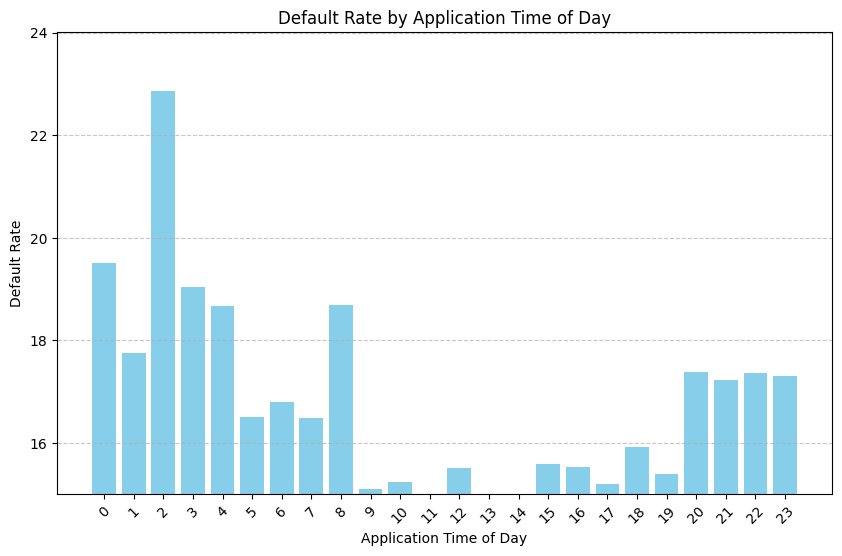

In [10]:
df_1 = df[(df['last_applied_loan_appln_time'] >= '2024-09-01') & (df['last_applied_loan_appln_time'] < '2025-12-01')]

# Calculate the default rate (percentage of target = 1) for each category
default_rate = df_1.groupby('last_applied_loan_time_of_day')['target_fspd30_flag'].agg(['sum', 'count']).reset_index()
default_rate['default_rate'] = default_rate['sum'] / default_rate['count']*100


# Plotting
plt.figure(figsize=(10, 6))
plt.bar(default_rate['last_applied_loan_time_of_day'], default_rate['default_rate'], color='skyblue')
plt.title('Default Rate by Application Time of Day')
plt.xlabel('Application Time of Day')
plt.ylabel('Default Rate')
plt.ylim(15, None)  # Set y-axis limit from 0 to 1 for percentage
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.xticks(ticks=default_rate['last_applied_loan_time_of_day'], rotation=45)

# Show the plot
plt.show()

In [11]:
bins = [-1,5,8,15,24]  # bins based on hour ranges
labels = ['12am-4am','5am-7am', '8am-2pm','2pm-12am']

# Cut the data into bins
df['last_applied_loan_time_of_day_cat']  =pd.cut(df['last_applied_loan_time_of_day'], bins=bins, labels=labels, right=False)

#### Mobile Initials

In [12]:
df['ln_mobile_no'] = df['last_applied_loan_mobile_no'].fillna(0).astype(float).astype(int).astype(str)
df['ln_mobile_initials'] = df['ln_mobile_no'].astype(str).str[-10:].str[:3]

df['ln_telconame'] = np.where(df['ln_mobile_initials'].isin(['904', '905', '906', '915', '916', '917', '926', '927', '935', '936', '937', '945', '952', '953', '954', '955', '956', '957', '958', '959', '965', '966', '967', '975', '976', '977', '978', '979', '995', '996', '997', '817', '917', '925']), 'Globe',
                            np.where(df['ln_mobile_initials'].isin(['813', '900', '907', '908', '909', '910', '911', '912', '913', '914', '918', '919', '920', '921', '928', '929', '930', '938', '939', '940', '946', '947', '948', '949', '950', '951', '960', '961', '963', '964', '968', '969', '970', '971', '980', '981', '982', '985', '989', '998', '999', '922', '923', '924', '925', '931', '932', '933', '934', '941', '942', '943', '944', '962', '972', '973', '974']), 'Smart',
                                np.where(df['ln_mobile_initials'].isin(['991', '992', '993', '994', '895', '896', '897', '898']), 'DITO',  'Other' )))

df['ln_telconame'].value_counts(dropna=False)

ln_telconame
Other    100594
Name: count, dtype: int64

#### Difference in Address given at Onboarding and birth place
##### (Match flags for Province, City, Barangay)

In [13]:
from fuzzywuzzy import fuzz

# df[['ln_city', 'onb_city']].apply(lambda row: fuzz.ratio(row['ln_city'].lower(), row['onb_city'].lower()), axis=1).value_counts(dropna=False).sort_index()

In [14]:
from fuzzywuzzy import fuzz
def fuzzy_match_columns(df, col1, col2, threshold=50):
    
    # Calculate fuzzy similarity and create a list of flags based on the threshold
    similarity_flags = df.apply(
        lambda row: 1 if fuzz.ratio(row[col1].lower(), row[col2].lower()) >= threshold else 0,
        axis=1
    ).tolist()
    
    return similarity_flags


location_list =[
'last_applied_loan_city',
'onb_place_of_birth'
]

df[location_list] = df[location_list].astype(str).apply(lambda x: x.str.lower())


df['diff_in_addrs_city_flag'] = fuzzy_match_columns(df, 'onb_place_of_birth', 'last_applied_loan_city', threshold=50)

df['diff_in_addrs_city_flag'].value_counts(dropna=False)

diff_in_addrs_city_flag
0    67626
1    32968
Name: count, dtype: int64

#### osversion_v2

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

def extract_version_number(version_str):
    """
    Extract the major version number from OS version string
    """
    try:
        # Remove 'ios' or 'android' prefix
        version = version_str.lower().replace('ios', '').replace('android', '')
        # Get the first number in the version string
        major_version = float(version.split('.')[0])
        return major_version
    except:
        return np.nan

def calculate_woe_iv_by_os(df, feature_col, target_col):
    """
    Calculate WOE separately for Android and iOS versions
    """
    # Create a copy to avoid modifying original dataframe
    df_copy = df.copy()
    
    # Split into OS type and extract version number
    df_copy['os_type'] = df_copy[feature_col].str.lower().apply(lambda x: 'ios' if 'ios' in str(x).lower() else 'android' if 'android' in str(x).lower() else np.nan)
    df_copy['version'] = df_copy[feature_col].apply(extract_version_number)
    
    results = {}
    ivs = {}
    
    # Calculate WOE for each OS type
    for os in ['android', 'ios']:
        os_df = df_copy[df_copy['os_type'] == os].copy()
        if len(os_df) == 0 or os_df['version'].isna().all():
            continue
            
        # Create crosstab for this OS type
        cross_tab = pd.crosstab(os_df['version'], os_df[target_col])
        
        # Calculate proportions
        good_dist = cross_tab[0] / cross_tab[0].sum()
        bad_dist = cross_tab[1] / cross_tab[1].sum()
        
        # Calculate WOE and IV
        woe = np.log(good_dist / bad_dist)
        iv = ((good_dist - bad_dist) * woe).sum()
        
        # Create summary DataFrame
        summary = pd.DataFrame({
            'Version': cross_tab.index,
            'Good': cross_tab[0],
            'Bad': cross_tab[1],
            'Total': cross_tab[0] + cross_tab[1],
            'Good_Rate': (cross_tab[0] / cross_tab[0].sum()).round(4),
            'Bad_Rate': (cross_tab[1] / cross_tab[1].sum()).round(4),
            'WOE': woe.round(4),
            'Bad_PCT': ((cross_tab[1] / (cross_tab[0] + cross_tab[1])) * 100).round(2)
        }).reset_index(drop=True)
        
        # Sort by version number
        summary = summary.sort_values('Version')
        
        results[os] = summary
        ivs[os] = iv
    
    return results.get('android'), results.get('ios'), ivs.get('android'), ivs.get('ios')

def plot_os_specific_woe(android_summary, ios_summary):
    """
    Create separate line plots for Android and iOS WOE values
    """
    plt.figure(figsize=(15, 10))
    
    # WOE line plots
    plt.subplot(2, 1, 1)
    if android_summary is not None:
        plt.plot(android_summary['Version'], android_summary['WOE'], 
                marker='o', label='Android', color='#32CD32', linewidth=2)
    if ios_summary is not None:
        plt.plot(ios_summary['Version'], ios_summary['WOE'], 
                marker='s', label='iOS', color='#1E90FF', linewidth=2)
    plt.title('Weight of Evidence by OS Version')
    plt.xlabel('Major Version Number')
    plt.ylabel('WOE')
    plt.grid(True, alpha=0.3)
    plt.legend()
    
    # Bad rate line plots
    plt.subplot(2, 1, 2)
    if android_summary is not None:
        plt.plot(android_summary['Version'], android_summary['Bad_PCT'], 
                marker='o', label='Android', color='#32CD32', linewidth=2)
    if ios_summary is not None:
        plt.plot(ios_summary['Version'], ios_summary['Bad_PCT'], 
                marker='s', label='iOS', color='#1E90FF', linewidth=2)
    plt.title('Bad Rate % by OS Version')
    plt.xlabel('Major Version Number')
    plt.ylabel('Bad Rate %')
    plt.grid(True, alpha=0.3)
    plt.legend()
    
    plt.tight_layout()
    plt.show()

def display_woe_tables(android_summary, ios_summary, android_iv, ios_iv):
    """
    Display formatted WOE tables for Android and iOS
    """
    print("\nAndroid WOE Summary:")
    print("-" * 80)
    if android_summary is not None:
        print(android_summary.to_string(index=False))
        print(f"\nAndroid Information Value: {round(android_iv, 4) if android_iv is not None else 'N/A'}")
    else:
        print("No Android data available")
    
    print("\niOS WOE Summary:")
    print("-" * 80)
    if ios_summary is not None:
        print(ios_summary.to_string(index=False))
        print(f"\niOS Information Value: {round(ios_iv, 4) if ios_iv is not None else 'N/A'}")
    else:
        print("No iOS data available")

def analyze_os_version_woe_separate(df):
    """
    Analyze WOE separately for Android and iOS versions
    """
    # Calculate WOE and IV for each OS type
    android_summary, ios_summary, android_iv, ios_iv = calculate_woe_iv_by_os(
        df, 'last_applied_loan_os_version', 'target_fspd30_flag'
    )
    
    # Display WOE tables
    display_woe_tables(android_summary, ios_summary, android_iv, ios_iv)
    
    # Create visualization
    plot_os_specific_woe(android_summary, ios_summary)
    
    return android_summary, ios_summary, android_iv, ios_iv

In [16]:
# Andr
# 3 - <=10 , 14
# 2 - 11,12,13
# 1 - 15
# ios 
# 3 - <=15, 19
# 2 - 17
# 1 - >=16,18,26


Android WOE Summary:
--------------------------------------------------------------------------------
 Version  Good  Bad  Total  Good_Rate  Bad_Rate     WOE  Bad_PCT
     6.0     1    0      1     0.0000    0.0000     inf     0.00
     9.0   656   94    750     0.0146    0.0109  0.2878    12.53
    10.0  1900  306   2206     0.0422    0.0356  0.1710    13.87
    11.0  4885  850   5735     0.1085    0.0988  0.0936    14.82
    12.0  5326  936   6262     0.1183    0.1088  0.0837    14.95
    13.0 10165 1959  12124     0.2257    0.2277 -0.0085    16.16
    14.0 15486 2880  18366     0.3439    0.3347  0.0271    15.68
    15.0  6281 1529   7810     0.1395    0.1777 -0.2421    19.58
    16.0   328   50    378     0.0073    0.0058  0.2259    13.23

Android Information Value: inf

iOS WOE Summary:
--------------------------------------------------------------------------------
 Version  Good  Bad  Total  Good_Rate  Bad_Rate     WOE  Bad_PCT
    14.0    10    1     11     0.0005    0.0003  0.

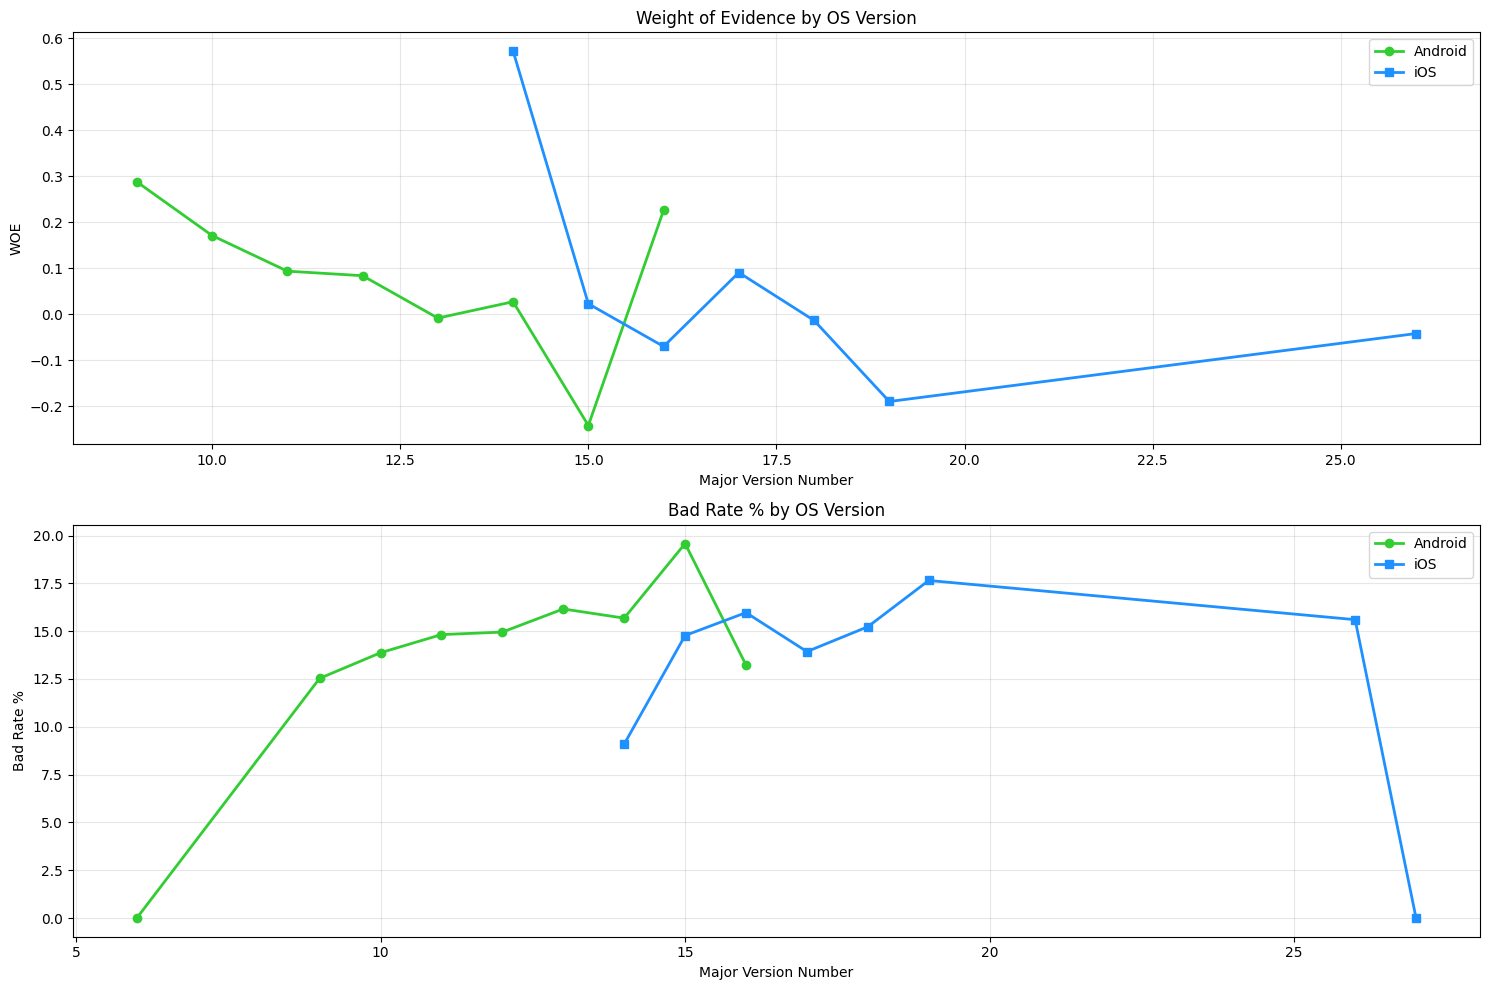

In [17]:
df_os = df[(df['last_applied_loan_appln_time'] >= '2024-09-01') & (df['last_applied_loan_appln_time'] < '2025-12-01')]
android_summary, ios_summary, android_iv, ios_iv = analyze_os_version_woe_separate(df_os)

In [18]:
df['loan_osversion_type'] = df['last_applied_loan_os_version'].str.extract(r'([a-zA-Z]+[0-9]+)')

df['loan_osversion_type'].unique()

array(['android13', 'android14', 'ios17', 'android12', 'android15',
       'ios18', 'android16', 'ios16', 'android11', 'android8',
       'android10', 'android9', 'ios15', 'ios26', 'android7', 'ios14',
       'android6', 'ios12', 'ios19', 'ios27', 'android17'], dtype=object)

In [19]:
# Andr
# 3 - <=10 , 14
# 2 - 11,12,13,16
# 1 - 15
# ios 
# 3 - <=15, 19
# 2 - 17
# 1 - >=16,18,26

In [20]:
df['loan_osversion_type'].unique()

array(['android13', 'android14', 'ios17', 'android12', 'android15',
       'ios18', 'android16', 'ios16', 'android11', 'android8',
       'android10', 'android9', 'ios15', 'ios26', 'android7', 'ios14',
       'android6', 'ios12', 'ios19', 'ios27', 'android17'], dtype=object)

In [21]:
# def get_os_version_type(os_version):

#     if 'android' in os_version:
#         os_type = 'android'
#         version = int(os_version.replace('android', ''))
#     elif 'ios' in os_version:
#         os_type = 'ios'
#         version = int(os_version.replace('ios', ''))
#     else:
#         os_type = 'other'
#         version = -1  # Use -1 for unrecognized types
#     return os_type, version

def get_os_version_type(os_version):

    if pd.isna(os_version):
        return 'other', -1

    os_version = str(os_version).lower()

    if os_version.startswith('android'):
        return 'android', int(os_version.replace('android', ''))

    elif os_version.startswith('ios'):
        return 'ios', int(os_version.replace('ios', ''))

    return 'other', -1

# Apply logic
def assign_osversion_type_order(os_version):

    os_type, version = get_os_version_type(os_version)

    
    
    if os_type == 'android':
        if version <= 10:
            return '3'
        elif version == 14:
            return '3'
        elif version in [11, 12,13,16]:
            return '2'
        elif version in [15]:
            return '1'
     
    elif os_type == 'ios':
        if version in [16,18,26]:
            return '1'
        elif version in [17]:
            return '2'
        elif version in [19]:
            return '3'
        elif version <= 15:
            return '3'
            
    return 'other'

df['loan_osversion_type_order'] = df['loan_osversion_type'].apply(assign_osversion_type_order)
df['loan_osversion_type_order'].unique()

array(['2', '3', '1', 'other'], dtype=object)

In [22]:
df['loan_osversion_type_order'].value_counts()

loan_osversion_type_order
2        44009
1        29158
3        27424
other        3
Name: count, dtype: int64

#### days_since_os_version_release

In [23]:
data_os = {
    "ln_os_type": ["Android"] * 11 + ["iOS"] * 9,
    "ln_version": [6, 7, 8, 9, 10, 11, 12, 13, 14, 15,16, 12, 13, 14, 15, 16, 17, 18,19, 26],
    "osversion_releasedate": [
        "October 5, 2015", "August 22, 2016", "August 21, 2017", "August 6, 2018", "September 3, 2019", 
        "September 8, 2020", "October 4, 2021", "August 15, 2022", "October 4, 2023", "September 3, 2025", "June 10, 2025",
        
        "September 17, 2018", "September 19, 2019", "September 16, 2020", "September 20, 2021", "September 12, 2022",
        "September 18, 2023", "September 16, 2024" ,"September 15, 2025", "September 15, 2025"
    ]
}

# Create DataFrame
df_os_releasedate = pd.DataFrame(data_os)

# Convert 'Release Date' to datetime and format as dd-mm-yyyy
df_os_releasedate["osversion_releasedate"] = pd.to_datetime(df_os_releasedate["osversion_releasedate"]).dt.strftime("%Y-%m-%d")

In [24]:
# df['ln_version'] = df['loan_osversion_type'].str.extract('(\d+)').astype(int)

df['ln_version'] = (
    df['loan_osversion_type']
    .str.extract(r'(\d+)', expand=False)
    .astype('Int64')
)

In [25]:
df = df.merge(df_os_releasedate[['ln_os_type', 'ln_version','osversion_releasedate']], left_on= ['last_applied_loan_os_type', 'ln_version'], right_on=['ln_os_type', 'ln_version'], how='left')

In [26]:
df['osversion_releasedate'] = pd.to_datetime(df['osversion_releasedate'])
df['last_applied_loan_appln_time'] = pd.to_datetime(df['last_applied_loan_appln_time'])

In [27]:
df['days_since_os_version_release'] = (df['last_applied_loan_appln_time'] - df['osversion_releasedate']).dt.days

In [28]:
df['osversion_releasedate'].isna().sum()

3

In [29]:
df[df['osversion_releasedate'].isna()][['osversion_releasedate', 'loan_osversion_type', 'ln_os_type', 'ln_version']]

,osversion_releasedate,loan_osversion_type,ln_os_type,ln_version
32534,NaT,ios27,NaN,27
48959,NaT,ios27,NaN,27
70854,NaT,android17,NaN,17


## Nature of work

In [30]:
df['ln_source_funds_new'] = df['last_applied_loan_source_funds_new'].str.lower().str.strip()
df['ln_employment_type_new'] = df['last_applied_loan_employment_type_new'].str.lower().str.strip()
df['ln_nature_of_work_new'] = df['last_applied_loan_nature_of_work_new'].str.lower().str.strip()
df['ln_industry_new'] = df['last_applied_loan_industry_new'].str.lower().str.strip()

In [31]:
df['ln_nature_of_work_new'].value_counts()

ln_nature_of_work_new
owner                                                          12008
licensed professional - others                                 11820
staff/rank and file                                             7006
govt employee                                                   6360
officer/supervisor                                              5311
sales/marketing personnel                                       4822
vendor (sari-sari store, wet market, etc)                       3747
manager/executive                                               3656
virtual/online/remote employee                                  2923
skilled worker                                                  2617
delivery rider / driver                                         2286
licensed professional - accountant                              1961
director/trustee/stockholder                                     189
government - uniformed service                                    92
broker/deale

In [32]:
nature_of_work_reference_map = {
    r'(?i)^licensed\s*professional(?:\s*[-/])?\s*others$': 'licensed professional - others',
    r'(?i)\bgov(?:ern(?:ment)?|t|n)\b': 'govt employee',
    r'(?i)^(?:sales(?:\s*/\s*|\s+)marketing\s+personnel|marketing\s+personnel)$': 'sales/marketing personnel',
    r'(?i)^licensed\s*professional(?:\s*[-/])?\s*accountant$': 'licensed professional - accountant',
    r'(?i)^owner$': 'owner',
    r'(?i)^(manager\s*/?\s*executive|manager|executive)$': 'manager/executive',
    r'(?i)\b(?:vendor(?:\s*\(.*?\))?|sari-sari\s*store|wet\s*market)\b' : 'vendor (sari-sari store, wet market, etc)',
    r'(?i)\b(?:virtual|online|remote)(?:\s*/\s*(?:virtual|online|remote))*\s+employee\b' : 'virtual/online/remote employee',
    r'(?i)\b(officer\s*/\s*supervisor|officer|supervisor)\b' : 'officer/supervisor',
    r'(?i)\b(staff\s*/\s*rank\s+and\s+file|staff|rank\s+and\s+file)\b' : 'staff/rank and file',
    r'(?i)^(broker\s*/?\s*dealer|broker|dealer)$': 'broker/dealer',
    r'(?i)\b(debt\s*collection|recovery\s*agents|collection\s*agency\s*employee)\b': 'debt collection/recovery agents/ collection agency employee',
    r'(?i)\blicensed\s*professional(?:\s*[-/])?\s*lawyer\b|\blawyer\b': 'licensed professional - lawyer',
    r'(?i)(drive|rider)' : 'delivery rider / driver',
    r'(?i)(skill)' : 'skilled worker'
}


# Initialize a new column with default value
df['ln_nature_of_work_new_bin'] = 'new'

# Apply mapping using np.where
for pattern, label in nature_of_work_reference_map.items():
    df['ln_nature_of_work_new_bin'] = np.where(df['ln_nature_of_work_new'].isna() | (df['ln_nature_of_work_new'] == ""), 'missing',
                                        np.where(df['ln_nature_of_work_new'].isin(['licensed professional - lawyer','broker/dealer','court personnel/bailiff','director/trustee/stockholder','debt collection/recovery agents/ collection agency employee','religious minister']), 'less_frequent_cat',
                                               np.where(df['ln_nature_of_work_new'].isin(['staff/rank and file', 'officer/supervisor']),'staff/rank and file/officer/supervisor',
                                                 np.where(df['ln_nature_of_work_new'].str.strip().str.lower().str.contains(pattern, regex=True),
        label, df['ln_nature_of_work_new_bin']
    ))))
    

In [33]:
df[['ln_nature_of_work_new_bin','ln_nature_of_work_new']].drop_duplicates()

,ln_nature_of_work_new_bin,ln_nature_of_work_new
0,staff/rank and file/officer/supervisor,staff/rank and file
1,owner,owner
3,missing,None
6,staff/rank and file/officer/supervisor,officer/supervisor
8,manager/executive,manager/executive
10,licensed professional - others,licensed professional - others
13,sales/marketing personnel,sales/marketing personnel
22,skilled worker,skilled worker
36,licensed professional - accountant,licensed professional - accountant
37,"vendor (sari-sari store, wet market, etc)","vendor (sari-sari store, wet market, etc)"


### source of fund

In [34]:
source_of_fund_reference_map = {
    r'(?i)\b(?:monthly\s+(salary|wage|stipend)|salary)\b': 'salary',
    r'(?i)(?:(income\s*from\s*business$)|(business(?:.*\s+income)?$))': 'income from business',
    r'(?i)\bremitt[ae]nce\b': 'remittance',
    r'(?i)\ballowance\b': 'allowance',
    r'(?i)^inheritance\s*/\s*retirement\s*funds$': 'inheritance/retirement funds',
    r'(?i)^pension$': 'pension',
    r'(?i)^interest\s*on\s*deposits(?:\s*and\s*investments)?$|^investments$': 'interest on deposits and investments'
}

# Initialize a new column with default value
df['ln_source_of_funds_new_bin'] = 'new'

# Apply mapping using np.where
for pattern, label in source_of_fund_reference_map.items():
    df['ln_source_of_funds_new_bin'] = np.where(df['ln_source_funds_new'].isna(), 'missing',
                                    np.where(df['ln_source_funds_new']=='others', 'missing',
                                              np.where(df['ln_source_funds_new'].isin(['allowance','pension','interest on deposits and investments','inheritance/retirement funds','donations']), 'less_frequent_cat',
                                             np.where(df['ln_source_funds_new'].str.strip().str.lower().str.contains(pattern, regex=True),
        label,
        df['ln_source_of_funds_new_bin']
    ))))

In [35]:
df['ln_source_funds_new'].value_counts()

ln_source_funds_new
salary                                  73237
income from business                    16993
remittance                               8996
allowance                                 341
pension                                    64
inheritance/retirement funds               33
interest on deposits and investments       26
donations                                   1
Name: count, dtype: int64

In [36]:
df[['ln_source_funds_new','ln_source_of_funds_new_bin']].drop_duplicates()

,ln_source_funds_new,ln_source_of_funds_new_bin
0,salary,salary
1,income from business,income from business
3,remittance,remittance
10,None,missing
364,allowance,less_frequent_cat
1577,inheritance/retirement funds,less_frequent_cat
3498,pension,less_frequent_cat
5158,interest on deposits and investments,less_frequent_cat
31460,donations,less_frequent_cat


## employment type

In [37]:

employment_reference_map = {
    r'(?i)^employed\s*-\s*(govt\.?|government)(?:\s*employee)?(?:\/(?:govt\.?|government)?\s*official)?$|^(?:govt\.?|government)\s*(?:employee|official)$':'employed - govt. employee/govt. official',
    r'(?i)\b(filipin[o|a])\s+worker\b|OFW': 'overseas filipino worker',
    r'(?i)^employed\s*-\s*private\s*(?:employee|employed)$|^private\s*(?:employee|employed)$':'employed - private employee',
    r'(?i)^self[-\s]*employed(?:\/private\s*practice)?$|^private\s*practice$':'self-employed/private practice',
    r'(?i)^remittance\s*beneficiary$': 'remittance beneficiary',
    r'(?i)^business\s*[-]?\s*owner$': 'business owner',
    # r'(?i)(retired)' : 'retired private/govt employee'
    # r'(?i)\bhouse\s*-?\s*(wife|husband)\b': 'housewife/househusband'
}



# Initialize a new column with default value
df['ln_employment_type_new_bin'] = 'new'

# Apply mapping using np.where
for pattern, label in employment_reference_map.items():
    df['ln_employment_type_new_bin'] = np.where(df['ln_employment_type_new'].isna(), 'missing',
                                            np.where(df['ln_employment_type_new'].isin(['unemployed','retired - private employee','retired govt. employee/ govt. official', 'retired - govt. employee/ govt. official','student','housewife/househusband','freelancer/independent contractor','overseas filipino worker','religious']), 'less_frequent_cat',
                                                np.where(df['ln_employment_type_new'].str.strip().str.lower().str.contains(pattern, regex=True),
                                                                label,
                                                                    df['ln_employment_type_new_bin']
    )))

In [38]:
df['ln_employment_type_new'].value_counts(dropna=False)

ln_employment_type_new
employed - private employee                 52640
employed - govt. employee/govt. official    13974
business owner                              12743
remittance beneficiary                       9115
self-employed/private practice               8987
employed - govt. employee                    2332
freelancer/independent contractor             277
overseas filipino worker                      274
housewife/househusband                        133
unemployed                                     55
retired - private employee                     30
student                                        19
retired govt. employee/ govt. official         13
religious                                       1
retired - govt. employee/ govt. official        1
Name: count, dtype: int64

In [39]:
df[['ln_employment_type_new','ln_employment_type_new_bin']].drop_duplicates()

,ln_employment_type_new,ln_employment_type_new_bin
0,employed - private employee,employed - private employee
1,business owner,business owner
3,remittance beneficiary,remittance beneficiary
4,employed - govt. employee/govt. official,employed - govt. employee/govt. official
10,self-employed/private practice,self-employed/private practice
58,employed - govt. employee,employed - govt. employee/govt. official
92,freelancer/independent contractor,less_frequent_cat
199,overseas filipino worker,less_frequent_cat
364,housewife/househusband,less_frequent_cat
806,student,less_frequent_cat


## Industry type

In [40]:

industry_desc_map = {
    # r'(?i)^business\s*process\s*outsourcing(?:/tele\s*marketing)?$|^tele\s*marketing$': 'business process outsourcing/tele marketing',
    r'(?i)(?:teleco|telco)': 'telecommunication',
    r'(?i)^others$': 'others',
    r'(?i)^(?:accounting|bookkeeping|auditing)(?:/bookkeeping)?(?:/auditing)?$': 'accounting/bookkeeping/auditing',
    r'(?i)^computer(?:/it\s*related\s*services)?$|^it\s*related\s*services$': 'computer/it related services',
    r'(?i)^(?:govt\.?|government\.?)(?:\s*institution)?$': 'govt. institution',
    r'(?i)^education(\s*/\s*private\s*schools|[\s]+private\s*schools)?$|^private\s*schools$': 'education/private schools',
    r'(?i)^(?:wholesale\s+and\s+)?retail\s+trade$': 'wholesale and retail trade',
    r'(?i)\b(beauty|health(?:\s+and\s+beauty)?(?:\s+services)?)\b': 'beauty and health services',
    r'(?i)^freight(?:\s+and\s+cargo)?$|^cargo$': 'freight and cargo',
    r'(?i)^transportation$': 'transportation',
    r'(?i)bank': 'banking',
    r'(?i)insurance': 'insurance activities',
    r'(?i)\b(recreation|arts|entertainment|media|sports)\b':  'recreation (arts, entertainment/media, sports)',
    r'(?i)\b(?:architecture\s*/\s*engineering|architecture|engineering)\b': 'architecture/engineering',
    r'(?i)^(?=.*\b(advertising|sales|marketing)\b)(?!.*tele\s*marketing).*': 
        'advertising/sales/marketing',
    r'(?i)^construction$': 'construction',
    r'(?i)\b(?:food\s*industry\s*/\s*restaurants\s*/\s*fastfoods|food\s*industry|restaurants|fastfoods)\b': 
        'food industry/restaurants/fastfoods',
    r'(?i)manufacturing': 'manufacturing',
    r'(?i)\b(?:hospital\s+and\s+medical\s+services|hospital|medical\s+services)\b': 'hospital and medical services',
    r'(?i)^real estate$': 'real estate',
    r'(?i)\b(?:tourism,\s*hotel\s+and\s+resorts|tourism|hotel\s+and\s+resorts|hotel|resorts)\b': 
        'tourism, hotel and resorts',
    r'(?i)\b(?:fin\s*tech\s*/\s*financial\s*services|fin\s*tech|financial\s*services)\b': 
        'fin tech/financial services',
    r'(?i)\b(?:maritime\s*/\s*shipping|maritime|shipping)\b': 'maritime/shipping',
    r'(?i)\b(?:manpower/manning\s*agencies|manpower|manning\s*agencies)\b': 'manpower/manning agencies',
    r'(?i)\b(?:legal\s*service/law\s*firm|legal\s*service|law\s*firm)\b': 'legal service/law firm',
    r'(?i)\b(?:pawnshop\s*/\s*remittance\s*agent\s*/\s*virtual\s*currency|pawnshop|remittance\s*agent|virtual\s*currency)\b': 
        'pawnshop/remittance agent/virtual currency',
    r'(?i)\b(?:utilities\s*\(?(?:electricity|gas|water)[^\)]*\)?|utilities|electricity|gas|water)\b': 
        'utilities (electricity, gas and water)',
    r'(?i)\b(?:ngos|non\s*profit\s*organization|foundation)\b': 'ngos/nonprofit organization/foundation',
    r'(?i)\b(?:airline|aviation)\b': 'airline/aviation',
    r'(?i)\b(?:agribusiness|animal\s*farming|fishing|agri)\b': 'agribusiness/animal farming/fishing',
    r"(?i)(?:convenience\s*store|internet\s*cafe'?s?)": "convenience store/internet cafe's",
    r'(?i)(?:gambling\s*and\s*betting|gambling|betting|online\s*gam|lottery|casino)': 
        'gambling and betting (online gaming, lottery, casino)',
    r'(?i)\b(?:gold|jewelry|precious\s*metals|art|antique\s*dealership)\b': 
        'gold/jewelry/precious metals/art/antique dealership',
    r'(?i)^religious organization$': 'religious organization',
    r'(?i)\b(?:fx\s*dealer\s*/?\s*money\s*changer|fx\s*dealer|money\s*changer)\b': 'fx dealer/money changer',
    r'(?i)\b(?:military and weaponry business|military|weaponry business)\b': 'military and weaponry business',
        r'(?i)\b(business\s*process\s*outsourcing\s*/?\s*tele\s*marketing|business\s*process\s*outsourcing|tele\s*marketing|BPO)\b': 'business process outsourcing/tele marketing',
    r'(?i)\b(housekeeping|sanitation|repair)\b' : 'repair, sanitation and housekeeping',
    r'(?i)\b(import\s*export\s*companies|import\s*compan\w*|export\s*compan\w*)\b' : 'import export companies',
    r'(?i)\b(mining\s+and\s+quarrying|mining|quarrying)\b' : 'mining and quarrying',
    r'(?i)\b(designated\s+nonfinancial\s+businesses|nonfinancial\s+businesses)\b' : 'designated nonfinancial businesses',
    # r'(?i)\b(housekeeping\s*/\s*sanitation\s*services|housekeeping|sanitation\s*services)\b' : 'housekeeping/sanitation services',
    r'(?i)(securities|holding)' : 'securities/holding companies',
    r'(?i)(club|disco|karaoke)' : 'nightclubs/discos/karaoke center',
    r'(?i)(paper)' : 'manufacture of paper and paper products',
    r'(?i)(carwash)' :'carwash'
    

}

# Initialize a new column with default value
df['ln_industry_new_cat'] = 'new'

# Apply mapping using np.where
for pattern, label in industry_desc_map.items():
    df['ln_industry_new_cat'] = np.where(df['ln_industry_new'].isna(), 'missing',
                                            # np.where(df['ln_industry_new'].isin(['airline/aviation', 'ngos/nonprofit organization/foundation','housekeeping/sanitation services', 'securities/holding companies','religious organization', 
                                            #                                     'fx dealer/money changer', 'car/boat/plane/used truck/autoparts manufacturing/dealership or auction houses', 'import export companies', 'designated nonfinancial businesses',
                                            #                                     'military and weaponry business', 'mining and quarrying','nightclubs/discos/karaoke center']), 'less_frequent_cat',
                                                    np.where( df['ln_industry_new'].str.strip().str.lower().str.contains(pattern, regex=True), label, df['ln_industry_new_cat']))



In [41]:
df[['ln_industry_new', 'ln_industry_new_cat']].drop_duplicates()

,ln_industry_new,ln_industry_new_cat
0,business process outsourcing/tele marketing,business process outsourcing/tele marketing
1,wholesale and retail trade,wholesale and retail trade
2,beauty and health services,beauty and health services
3,None,missing
4,banking,banking
11,"tourism, hotel and resorts","tourism, hotel and resorts"
12,others,others
14,manufacturing,manufacturing
16,construction,construction
18,food industry/restaurants/fastfoods,food industry/restaurants/fastfoods


In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm


def calculate_woe_iv_by_os(df, feature_col, target_col):
    """
    Calculate WOE separately for Android and iOS versions
    """
    # Create a copy to avoid modifying original dataframe
    df_copy = df.copy()
    
    results = {}
    ivs = {}
    
 

    # Create crosstab for this OS type
    cross_tab = pd.crosstab(df['ln_industry_new_cat'], df[target_col])

    # Calculate proportions
    good_dist = cross_tab[0] / cross_tab[0].sum()
    bad_dist = cross_tab[1] / cross_tab[1].sum()

    # Calculate WOE and IV
    woe = np.log(good_dist / bad_dist)
    iv = ((good_dist - bad_dist) * woe).sum()

    # Create summary DataFrame
    summary = pd.DataFrame({
        'Industry': cross_tab.index,
        'Good': cross_tab[0],
        'Bad': cross_tab[1],
        'Total': cross_tab[0] + cross_tab[1],
        'Good_Rate': (cross_tab[0] / cross_tab[0].sum()).round(4),
        'Bad_Rate': (cross_tab[1] / cross_tab[1].sum()).round(4),
        'WOE': woe.round(4),
        'Bad_PCT': ((cross_tab[1] / (cross_tab[0] + cross_tab[1])) * 100).round(2)
    }).reset_index(drop=True)

    # Sort by version number
    summary = summary.sort_values('Industry')

    results = summary
    ivs = iv
    
    return results, ivs

def plot_os_specific_woe(android_summary):
    plt.figure(figsize=(15, 10))

    # Normalize the data for color mapping
    if android_summary is not None:
        industries = android_summary['Industry']
        woe_values = android_summary['WOE']
        bad_rate_values = android_summary['Bad_PCT']

        # WOE bar plot with gradient
        plt.subplot(2, 1, 1)
        # cmap = cm.get_cmap('Greens')  # Use a green gradient colormap
        cmap = plt.get_cmap('Greens')
        colors = cmap(np.linspace(0.4, 1, len(woe_values)))  # Adjust gradient range
        plt.bar(industries, woe_values, color=colors, label='Industry', alpha=0.9)
        plt.title('Weight of Evidence by Industry')
        plt.xlabel('Major Version Number')
        plt.ylabel('WOE')
        plt.grid(True, axis='y', alpha=0.3)
        plt.legend()

        # Bad Rate bar plot with gradient
        plt.subplot(2, 1, 2)
        # cmap = cm.get_cmap('Greens')  # Use an orange gradient colormap
        cmap = plt.get_cmap('Greens')
        colors = cmap(np.linspace(0.4, 1, len(bad_rate_values)))  # Adjust gradient range
        plt.bar(industries, bad_rate_values, color=colors, label='Industry', alpha=0.9)
        plt.title('Bad Rate % by Industry')
        plt.xlabel('Major Version Number')
        plt.ylabel('Bad Rate %')
        plt.grid(True, axis='y', alpha=0.3)
        plt.legend()

    plt.tight_layout()
    plt.show()


def display_woe_tables(android_summary, android_iv):
    """
    Display formatted WOE tables for Industry
    """
    print("\nIndustry WOE Summary:")
    print("-" * 80)
    if android_summary is not None:
        print(android_summary.to_string(index=False))
        print(f"\nIndustry Information Value: {round(android_iv, 4) if android_iv is not None else 'N/A'}")
    else:
        print("No Industry data available")
    
    print("\nIndustry WOE Summary:")
    print("-" * 80)


def analyze_os_version_woe_separate(df):
    """
    Analyze WOE separately for Industry
    """
    # Calculate WOE and IV for each OS type
    android_summary, android_iv = calculate_woe_iv_by_os(
        df, 'loan_industry_new_cat', 'target_fpd30_flag'
    )
    
    # Display WOE tables
    display_woe_tables(android_summary, android_iv)
    
    # Create visualization
    plot_os_specific_woe(android_summary)
    
    return android_summary, android_iv


Industry WOE Summary:
--------------------------------------------------------------------------------
                                             Industry  Good  Bad  Total  Good_Rate  Bad_Rate     WOE  Bad_PCT
                      accounting/bookkeeping/auditing  1006   73   1079     0.0140    0.0100  0.3404     6.77
                          advertising/sales/marketing  1472  200   1672     0.0205    0.0273 -0.2869    11.96
                  agribusiness/animal farming/fishing   758   59    817     0.0105    0.0080  0.2702     7.22
                                     airline/aviation    98    5    103     0.0014    0.0007  0.6926     4.85
                             architecture/engineering   461   48    509     0.0064    0.0065 -0.0207     9.43
                                              banking  1822  180   2002     0.0253    0.0245  0.0318     8.99
                           beauty and health services  1053  100   1153     0.0146    0.0136  0.0713     8.67
          busine

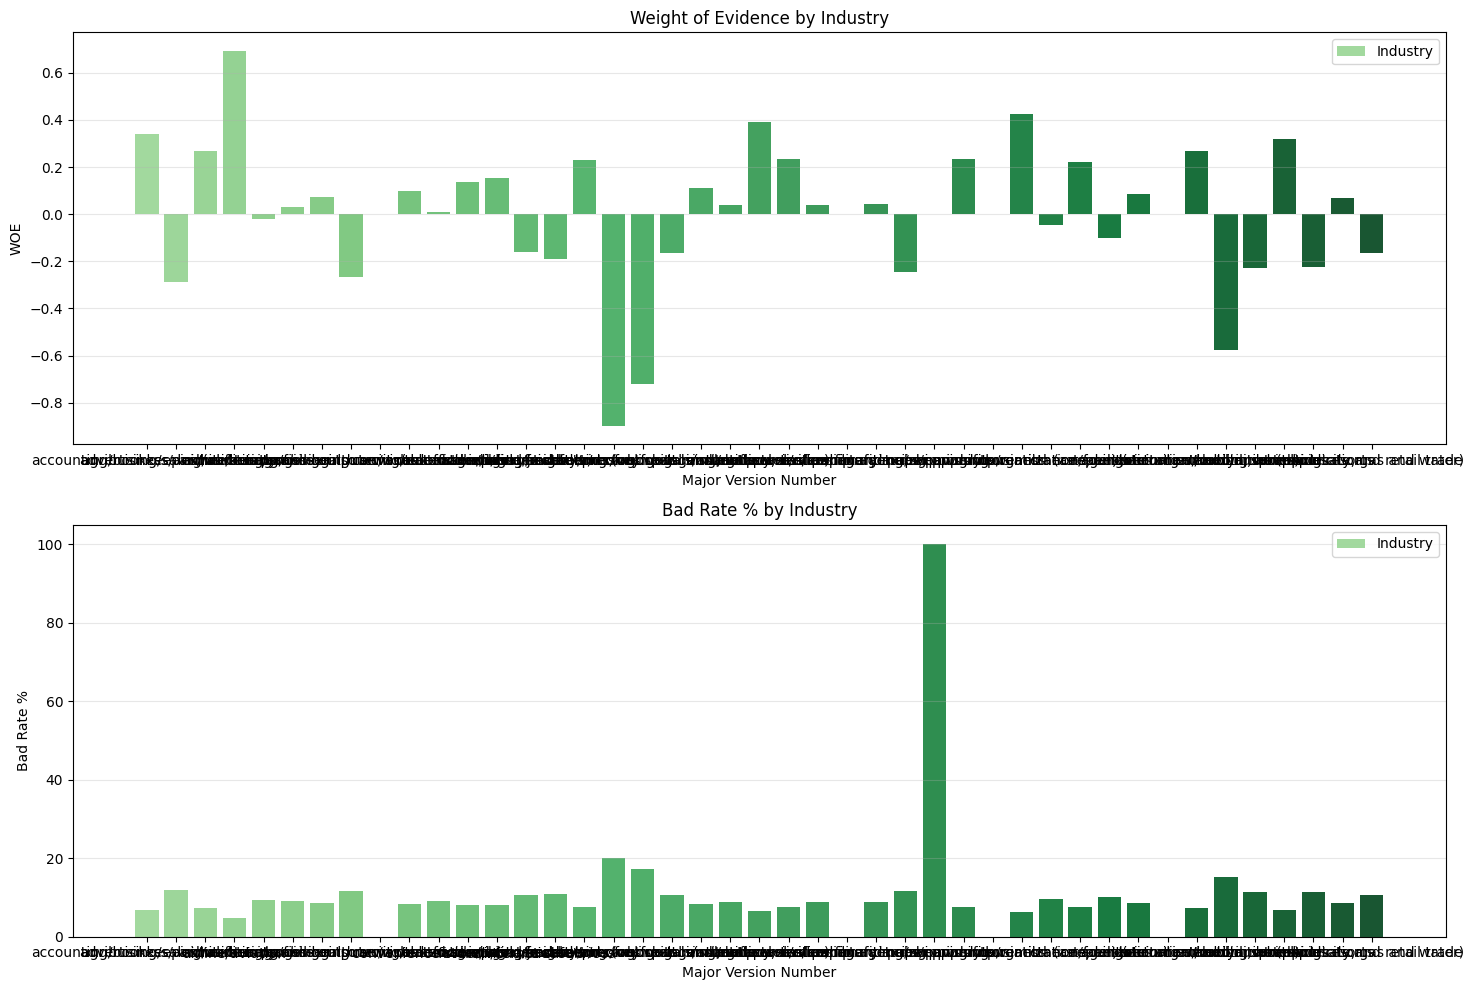

In [43]:
df_industry = df[(df['last_applied_loan_appln_time'] >= '2024-09-01') & (df['last_applied_loan_appln_time'] < '2026-08-17')]
android_summary, android_iv = analyze_os_version_woe_separate(df_industry)

In [44]:
# Assuming android_summary is your DataFrame

print("\nIndustries with  Bad_PCT <= 8:")
print(android_summary[android_summary['Bad_PCT'] <= 8]['Industry'].unique().tolist())

print("\nIndustries with 5 < Bad_PCT <= 10:")
print(android_summary[(android_summary['Bad_PCT'] >8 ) & (android_summary['Bad_PCT'] <= 10)]['Industry'].unique().tolist())

print("\nIndustries with Bad_PCT >10:")
print(android_summary[(android_summary['Bad_PCT'] >10 ) ]['Industry'].unique().tolist())


Industries with  Bad_PCT <= 8:
['accounting/bookkeeping/auditing', 'agribusiness/animal farming/fishing', 'airline/aviation', 'carwash', 'freight and cargo', 'insurance activities', 'legal service/law firm', 'manufacture of paper and paper products', 'missing', 'new', 'ngos/nonprofit organization/foundation', 'pawnshop/remittance agent/virtual currency', 'religious organization', 'repair, sanitation and housekeeping', 'tourism, hotel and resorts']

Industries with 5 < Bad_PCT <= 10:
['architecture/engineering', 'banking', 'beauty and health services', 'computer/it related services', 'construction', "convenience store/internet cafe's", 'education/private schools', 'govt. institution', 'hospital and medical services', 'manpower/manning agencies', 'manufacturing', 'others', 'recreation (arts, entertainment/media, sports)', 'utilities (electricity, gas and water)']

Industries with Bad_PCT >10:
['advertising/sales/marketing', 'business process outsourcing/tele marketing', 'fin tech/financ

In [45]:
df['loan_industry_new_cat_bin'] = np.where(
    df['ln_industry_new_cat'].isna(), np.nan,
            np.where(df['ln_industry_new_cat'].isin(['military and weaponry business','accounting/bookkeeping/auditing', 'airline/aviation', 'carwash', 'freight and cargo', 'fx dealer/money changer', 'insurance activities', 'legal service/law firm', 'manufacture of paper and paper products', 'religious organization', 'tourism, hotel and resorts', 'utilities (electricity, gas and water)']), 3,
                np.where(df['ln_industry_new_cat'].isin(['banking', 'computer/it related services', 'education/private schools', 'manpower/manning agencies', 'missing', 'ngos/nonprofit organization/foundation', 'repair, sanitation and housekeeping']), 2,
                    np.where(df['ln_industry_new_cat'].isin(['advertising/sales/marketing', 'agribusiness/animal farming/fishing', 'architecture/engineering', 'beauty and health services', 'business process outsourcing/tele marketing', 'construction', "convenience store/internet cafe's", 'fin tech/financial services', 'food industry/restaurants/fastfoods', 'gambling and betting (online gaming, lottery, casino)', 'gold/jewelry/precious metals/art/antique dealership', 'govt. institution', 'hospital and medical services', 'manufacturing', 'maritime/shipping', 'others', 'pawnshop/remittance agent/virtual currency', 'real estate', 'recreation (arts, entertainment/media, sports)', 'securities/holding companies', 'telecommunication', 'transportation', 'wholesale and retail trade']), 1,
                             np.where(df['ln_industry_new_cat'] == 'nan',None, 'New')
                    )
                )
            )
        )

df['loan_industry_new_cat_bin'].value_counts(dropna=False)

loan_industry_new_cat_bin
1      62304
2      34177
3       4108
New        5
Name: count, dtype: int64

#### Combining feature values 

In [46]:

doc_type_reference_map = {
   r'(?i)(Driving|Drive|DL)': 'driving license',
    r'(?i)(?:)(UMID)': 'umid',
    r'(?i)(?:)(ePassport|Passport)': 'passport',
    r'(?i)(?:)(Post)': 'postal id card',
    r'(?i)(?:)(Social Sec|SSS|security)': 'social security card',
    r'(?i)(professional(?:\s*-\s*|\s)id|prc)': 'professional id card',
    r'(?i)^(?:philippines\s*[-]?\s*)?(digital(?:\s+or\s+ephilsys)?\s+id|ephilsys|philid|nation|ePhil|egov|national\s+id|id)': 'national id',
    r'(?i)(health|mdei|medical|medicard|philhealth)': 'health card',
    r'(?i)(voter\s*card|voter|voting\s*card)': 'voter card',
    r'(?i)tax': 'tax card'
}


# Initialize a new column with default value
df['ln_doc_type_rolled'] = 'new'

# Apply mapping using np.where
for pattern, label in doc_type_reference_map.items():
    df['ln_doc_type_rolled'] = np.where(df['last_applied_loan_doc_type'].isna() , 'missing',
                                             np.where(df['last_applied_loan_doc_type'].str.strip().str.lower().str.contains(pattern, regex=True),
        label,
        df['ln_doc_type_rolled']
    ))
    

In [47]:
df[['last_applied_loan_doc_type','ln_doc_type_rolled']].drop_duplicates()

,last_applied_loan_doc_type,ln_doc_type_rolled
0,Philippines - Id Card (2020),national id
1,Philippines - Social Security Card #1,social security card
3,Philippines - Driving License (2022),driving license
6,Philippines - ePassport,passport
7,Philippines - Driving License,driving license
9,Philippines - Voter Card,voter card
10,Philippines - UMID Card,umid
13,Philippines - UMID Card #1,umid
16,Philippines - UMID Card (2016),umid
25,Philippines - Postal Id Card,postal id card


#### Email Flag

In [48]:
from fuzzywuzzy import fuzz

def fuzzy_match_name_email(row, threshold=80):
    # Convert all fields to string safely and handle NaN/None
    first_name = str(row['onb_first_name']) if pd.notna(row['onb_first_name']) else ''
    middle_name = str(row['onb_middle_name']) if pd.notna(row['onb_middle_name']) else ''
    last_name = str(row['onb_last_name']) if pd.notna(row['onb_last_name']) else ''
    email = str(row['onb_email']) if pd.notna(row['onb_email']) else ''

    if '@' not in email:
        return 0  # Skip malformed emails

    email_local = email.split('@')[0].lower()

    # Calculate similarity scores
    first_name_score = fuzz.partial_ratio(first_name.lower(), email_local)
    if first_name_score > threshold:
        return first_name_score

    middle_name_score = fuzz.partial_ratio(middle_name.lower(), email_local) if middle_name else 0
    if middle_name_score > threshold:
        return middle_name_score

    last_name_score = fuzz.partial_ratio(last_name.lower(), email_local)
    if last_name_score > threshold:
        return last_name_score

    return max(first_name_score, middle_name_score, last_name_score)

    
df['onb_name_email_match_score'] = df.apply(fuzzy_match_name_email, axis=1)

#### Email Domain

In [49]:
def email_func(df):
    X_transformed = df.copy()
    X_transformed['domain'] = X_transformed['onb_email'].apply(lambda x: x.lower().split('@')[1])
    X_transformed['email_secondary_domain'] = X_transformed['domain'].apply(lambda x: x.lower().split('.')[-1])
    X_transformed = X_transformed.drop(columns=['onb_email'])
    return X_transformed

# Fit the transformer (learn domain frequencies)
transformed_df = email_func(df[['id_digitalloanaccountid', 'onb_email']])

In [50]:
df = df.merge(transformed_df, on=['id_digitalloanaccountid'], how='left')

In [51]:
df['email_primary_domain'] = np.where(df['domain'].str.contains('gmail|googlemail', case=False), 'gmail.com',
                        np.where(df['domain'].str.contains('yahoo|ymail|rocketmail', case=False), 'yahoo.com',
                                 'other'))

df['email_primary_domain'].value_counts(dropna=False)

email_primary_domain
gmail.com    89541
yahoo.com     8975
other         2078
Name: count, dtype: int64

#### Role up City

In [52]:
df_test_transformed = df.copy()

df_test_transformed['ln_city'] =  df_test_transformed['last_applied_loan_city'].str.lower()

ln_city = df_test_transformed[(df_test_transformed['dt_loan_appln_dtime'] >= '2024-09-01') & (df['dt_loan_appln_dtime'] < '2025-12-01')]
ln_city = pd.DataFrame(ln_city['ln_city'].value_counts(dropna=False)).reset_index()
ln_city.columns = ['ln_city', 'Count']

ln_city['ln_city_cat'] = np.where(ln_city['Count']>=600, ln_city['ln_city'],'Others')

df_test_transformed = df_test_transformed.merge(ln_city[['ln_city', 'ln_city_cat']], on=['ln_city'], how='left')

In [53]:
ln_city['ln_city_cat'].unique().tolist()

['quezon city',
 'city of caloocan',
 'city of taguig',
 'city of manila',
 'city of makati',
 'city of pasig',
 'city of mandaluyong',
 'antipolo',
 'city of valenzuela',
 'dasmarinas',
 'san jose del monte',
 'cebu city',
 'city of paranaque',
 'city of marikina',
 'city of muntinlupa',
 'imus',
 'general trias',
 'rodriguez  montalban',
 'bacoor',
 'city of las pinas',
 'santa rosa',
 'binangonan',
 'city of malabon',
 'calamba',
 'tanza',
 'cainta',
 'pasay city',
 'davao city',
 'lipa city',
 'san pedro',
 'Others']

In [54]:
city_list = ['quezon city',
 'city of manila',
 'city of caloocan',
 'city of taguig',
 'city of pasig',
 'city of makati',
 'city of mandaluyong',
 'antipolo',
 'cebu city',
 'city of paranaque',
 'city of valenzuela',
 'city of marikina',
 'city of las pinas',
 'bacoor',
 'dasmarinas',
 'imus',
 'davao city',
 'Others']
             

df['ln_city'] =  df['last_applied_loan_city'].str.lower()
df['ln_city_cat'] = np.where(df['ln_city'].isnull(), np.nan,
                             np.where(df['ln_city'].isin(city_list), df['ln_city'], 'others'))

df['ln_city_cat'].value_counts(dropna=False)

ln_city_cat
others                 63394
quezon city             5805
city of caloocan        3830
city of taguig          3214
city of manila          2573
city of makati          2346
city of pasig           2336
city of mandaluyong     2141
antipolo                2117
city of valenzuela      1889
dasmarinas              1670
cebu city               1633
city of marikina        1496
city of paranaque       1451
imus                    1318
city of las pinas       1226
bacoor                  1215
davao city               940
Name: count, dtype: int64

#### Role up brand

In [55]:
df_test_transformed['ln_brand'] =  df_test_transformed['last_applied_loan_device_brand'].str.lower()

ln_brand = df_test_transformed[(df_test_transformed['dt_loan_appln_dtime'] >= '2024-09-01') & (df['dt_loan_appln_dtime'] < '2025-12-01')]
ln_brand = pd.DataFrame(ln_brand['ln_brand'].value_counts()).reset_index()
ln_brand.columns = ['ln_brand', 'Count']

ln_brand['ln_brand_cat'] = np.where(ln_brand['Count']>=100, ln_brand['ln_brand'],'Others')

df_test_transformed = df_test_transformed.merge(ln_brand[['ln_brand', 'ln_brand_cat']], on=['ln_brand'], how='left')

In [56]:
ln_brand['ln_brand_cat'].unique().tolist()

['apple',
 'samsung',
 'oppo',
 'vivo',
 'realme',
 'redmi',
 'infinix',
 'tecno',
 'honor',
 'xiaomi',
 'huawei',
 'poco',
 'itel',
 'Others']

In [57]:
brand_list = ['apple',
 'samsung',
 'oppo',
 'vivo',
 'realme',
 'redmi',
 'infinix',
 'honor',
 'tecno',
 'xiaomi',
 'poco',
 'huawei',
 'itel',
 'Others']
             
df['ln_brand'] =  df['last_applied_loan_device_brand'].str.lower()              
df['ln_brand_cat'] =   np.where(df['ln_brand'].isin(brand_list),df['ln_brand'],
                                                          np.where(df['ln_brand'].isnull(),None, 'others'))

df['ln_brand_cat'].value_counts(dropna=False)

ln_brand_cat
apple      28756
samsung    15848
oppo       12402
vivo       10958
realme      7941
infinix     5870
redmi       5857
tecno       3676
honor       3346
xiaomi      1467
poco        1439
huawei      1361
others       919
itel         754
Name: count, dtype: int64

#### Role up Province

In [58]:
df_test_transformed['ln_province'] =  df_test_transformed['last_applied_loan_province'].str.lower()

ln_province = df_test_transformed[(df_test_transformed['dt_loan_appln_dtime'] >= '2024-09-01') & (df['dt_loan_appln_dtime'] < '2025-12-01')]
ln_province = pd.DataFrame(ln_province['ln_province'].value_counts()).reset_index()

ln_province.columns = ['ln_province', 'Count']

ln_province['ln_province_cat'] = np.where(ln_province['Count']>=400, ln_province['ln_province'],'Others')

df_test_transformed = df_test_transformed.merge(ln_province[['ln_province', 'ln_province_cat']], on=['ln_province'], how='left')


In [59]:
ln_province['ln_province_cat'].unique().tolist()

['metro manila',
 'cavite',
 'rizal',
 'bulacan',
 'laguna',
 'cebu',
 'batangas',
 'pampanga',
 'quezon',
 'davao del sur',
 'tarlac',
 'camarines sur',
 'negros occidental',
 'nueva ecija',
 'leyte',
 'bataan',
 'iloilo',
 'albay',
 'Others']

In [60]:
province_list = ['metro manila',
 'cavite',
 'rizal',
 'laguna',
 'bulacan',
 'cebu',
 'batangas',
 'pampanga',
 'davao del sur',
 'negros occidental',
 'quezon',
 'Others']

df['ln_province'] =  df['last_applied_loan_province'].str.lower()
df['ln_province_cat'] =  np.where(df['ln_province'].isin(province_list),df['ln_province'],
                                                          np.where(df['ln_province'].isnull(), None, 'others'))

df['ln_province_cat'].value_counts(dropna=False)

ln_province_cat
metro manila         32797
others               12593
cavite               11583
rizal                 9169
bulacan               8147
laguna                7604
cebu                  5877
batangas              5694
pampanga              3671
quezon                1582
davao del sur         1040
negros occidental      837
Name: count, dtype: int64

#### Cnt_dependents

In [61]:
df['ln_cnt_dependents'] = np.where(df['last_applied_loan_cnt_dependents'].isin(['4','5 or more']), 'Others',
                                                      df['last_applied_loan_cnt_dependents'])

df['ln_cnt_dependents'].value_counts(dropna=False)

ln_cnt_dependents
No dependents    41056
1                24535
2                21327
3                 9339
Others            3854
None               483
Name: count, dtype: int64

## ln_marital_status

In [62]:
df['ln_marital_status']= np.where(df['last_applied_loan_marital_status'].isin(['Live-in Partner','With a Live-in Partner']), 'With a Live-in Partner', df['last_applied_loan_marital_status'])

#### ln_age_observation_date

In [63]:
df['dob'] = pd.to_datetime(df['onb_dob'])
df['last_applied_loan_appln_time'] = pd.to_datetime(df['last_applied_loan_appln_time'])

df['ln_age_observation_date'] = (df['last_applied_loan_appln_time'] - df['dob']).dt.days // 365.25

## days_on_book

In [64]:
# Ensure it is an independent dataframe copy
df = df.copy()

# Standardize to UTC to prevent timezone mixing errors
df['last_applied_loan_appln_time'] = pd.to_datetime(df['last_applied_loan_appln_time'], errors='coerce', utc=True)
df['onboarding_datetime'] = pd.to_datetime(df['dt_onb_dtime'], errors='coerce', utc=True)

# Calculate absolute days and handle empty values safely
df['days_on_book'] = (df['last_applied_loan_appln_time'] - df['onboarding_datetime']).dt.days.abs()


In [65]:
# df['last_applied_loan_appln_time'] = pd.to_datetime(df['last_applied_loan_appln_time'], errors='coerce')
# df['onboarding_datetime'] = pd.to_datetime(df['dt_onb_dtime'], errors='coerce')

# df['days_on_book'] = (df['last_applied_loan_appln_time'] - df['onboarding_datetime']).dt.days.abs()

In [66]:
df1 = df[['id_customerid', 'dt_obs_date','last_applied_loan_time_of_day', 'last_applied_loan_day_of_week', 'last_applied_loan_Is_Weekend', 'last_applied_loan_time_of_day_cat', 'ln_mobile_no', 
'ln_mobile_initials', 'ln_telconame', 'diff_in_addrs_city_flag', 'loan_osversion_type', 'loan_osversion_type_order', 'ln_version', 'ln_os_type', 'osversion_releasedate', 
'days_since_os_version_release', 'ln_source_funds_new', 'ln_employment_type_new', 'ln_nature_of_work_new', 'ln_industry_new', 'ln_nature_of_work_new_bin', 'ln_source_of_funds_new_bin', 
'ln_employment_type_new_bin', 'ln_industry_new_cat', 'loan_industry_new_cat_bin', 'ln_doc_type_rolled', 'onb_name_email_match_score', 'domain', 'email_secondary_domain', 'email_primary_domain', 
'ln_city', 'ln_city_cat', 'ln_brand', 'ln_brand_cat', 'ln_province', 'ln_province_cat', 'ln_cnt_dependents', 'ln_marital_status', 'dob', 'ln_age_observation_date', 'onboarding_datetime', 
'days_on_book']].copy()

In [67]:
def convert_datetime_columns(df):
    for col in df.columns:
        col_type = str(df[col].dtype).lower()
        
        # Handle date/time types
        if 'dbdate' in col_type or 'date' in col_type:
            try:
                df[col] = pd.to_datetime(df[col])
            except:
                pass
        elif 'dbtime' in col_type or 'time' in col_type:
            try:
                df[col] = pd.to_datetime(df[col], format='%H:%M:%S').dt.time
            except:
                pass
        elif 'dbtimestamp' in col_type or 'timestamp' in col_type:
            try:
                df[col] = pd.to_datetime(df[col])
            except:
                pass

convert_datetime_columns(df1)
dd.query("""select id_customerid||dt_obs_date, count(id_customerid||dt_obs_date)cnt from df1 group by 1 having cnt > 1 order by 2 desc""").to_df()

,(id_customerid || dt_obs_date),cnt


In [69]:
csv_filename = "cash_demo_bscore_feature_creation"
df1.to_csv(fr"{UTIL_PATH}\data\{csv_filename}.csv", index=False)

In [70]:
print(list(df.columns))

['id_customerid', 'dt_onb_dtime', 'seg_loan_rank', 'id_digitalloanaccountid', 'id_loanaccountnumber', 'dt_loan_appln_dtime', 'dt_loan_disb_dtime', 'dt_obs_date', 'target_fpd10_flag', 'target_fpd15_flag', 'target_fpd30_flag', 'target_fspd30_flag', 'target_fstpd30_flag', 'target_spd30_flag', 'target_tpd30_flag', 'target_mature_fpd10_flag', 'target_mature_fpd15_flag', 'target_mature_fpd30_flag', 'target_mature_fspd30_flag', 'target_mature_fstpd30_flag', 'last_applied_loan_prod_type', 'last_loan_amount', 'last_loan_tenor', 'seg_with_active_loan_flag', 'tx_cust_dpd_status', 'seg_is_upsell_pilot_flag', 'last_applied_loan_digitalloanaccountid', 'Last_applied_loan_appln_submit_datetime', 'last_disb_loan_digitalloanaccountid', 'last_disb_loan_appln_submit_datetime', 'id_last_disb_loan_loanaccountnumber', 'onb_email_verified_flag', 'onb_place_of_birth', 'onb_doc_type', 'onb_country', 'onb_province', 'onb_city', 'onb_barangay', 'onb_postalcode', 'onb_latitude', 'onb_longitude', 'onb_osversion', '

In [71]:
df1["loan_industry_new_cat_bin"] = df1["loan_industry_new_cat_bin"].astype(str)

# Create Table

In [72]:
# Upload to BigQuery
table_id = f"{demo_features}"
job_config = bigquery.LoadJobConfig(
    write_disposition="WRITE_TRUNCATE",  # or "WRITE_APPEND"
)
job = client.load_table_from_dataframe(df1, table_id, job_config=job_config)
job.result()  # Wait for the job to complete

LoadJob<project=prj-prod-dataplatform, location=asia-southeast1, id=6ed54531-59f6-4ac5-a439-3942397cd095>

In [73]:
print(table_id)

dap_ds_poweruser_playground.bscore_demo_features_v28


In [74]:
table = client.get_table(f"{demo_features}")

print("Total columns:", len(table.schema))
print("Total rows:", table.num_rows)

Total columns: 42
Total rows: 100594
